# Multimodal RAG Lab — Scenario 1: Text-Only Proxy (OCR + VLM Captioning)

**Architecture 1 Pipeline:**
- **Ingestion:** `Image` $\rightarrow$ `Pre-process (OpenCV)` $\rightarrow$ `Extract Text (OCR) + Describe Visuals (VLM)` $\rightarrow$ `Summarize (Qwen2.5-1.5B)` $\rightarrow$ `Embed Summary Text (all-MiniLM-L6-v2)` $\rightarrow$ `Store Vector + Image Path in Qdrant`
- **Retrieval:** `User Text Query` $\rightarrow$ `Text Embedding (all-MiniLM-L6-v2)` $\rightarrow$ `Cosine Similarity Search against Summary Vectors` $\rightarrow$ `Fetch & Display Linked Original Image`

## Step 1: Load Image & Pre-process with OpenCV (`cv2`)
We load `Document/IVI_Data.jpg`, convert it to grayscale, enhance local contrast using **CLAHE** (Contrast Limited Adaptive Histogram Equalization), and apply mild denoising so the OCR engine can read every button label accurately.

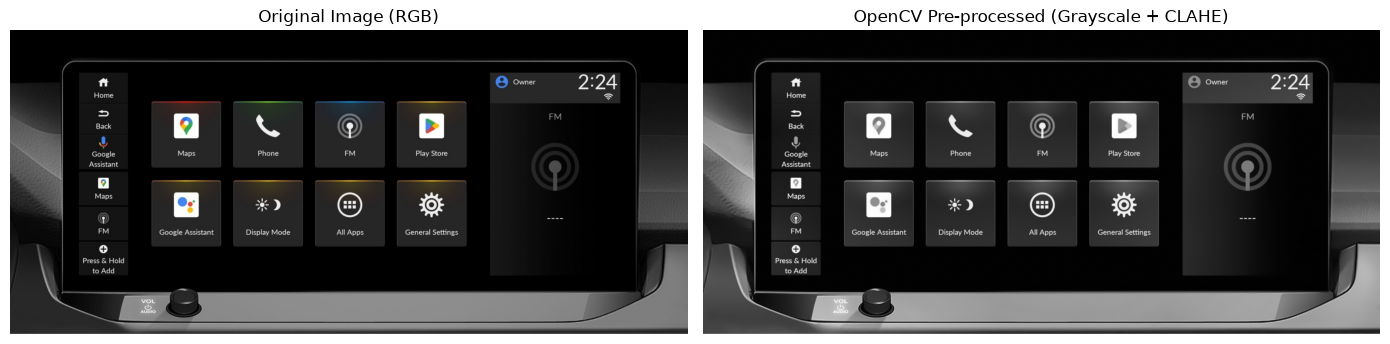

In [1]:
# Import Path for OS-safe file path handling and gc for memory management on 8GB RAM
import gc
from pathlib import Path

# Import OpenCV for image pre-processing and Matplotlib for visualization
import cv2
import matplotlib.pyplot as plt

# Define the absolute path to your Honda IVI dataset image
IMAGE_PATH = Path(r"D:\multimodel-rag-lab\Document\IVI_Data.jpg")

# Ensure the file exists before running the pipeline
assert IMAGE_PATH.exists(), f"File not found: {IMAGE_PATH}"

# Read the image from disk using OpenCV (loads in BGR color order by default)
img_bgr = cv2.imread(str(IMAGE_PATH))

# Convert BGR to RGB so we can display the true colors in Matplotlib
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

# Convert BGR to Grayscale (1 channel) because OCR works best on high-contrast intensity values
img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

# Create a CLAHE object to boost local contrast across the dark infotainment screen
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

# Apply CLAHE contrast enhancement to the grayscale image
img_clahe = clahe.apply(img_gray)

# Apply mild non-local means denoising to remove JPEG compression artifacts around small letters
img_preprocessed = cv2.fastNlMeansDenoising(img_clahe, None, h=10, templateWindowSize=7, searchWindowSize=21)

# Visualize Original vs. OpenCV Pre-processed image side-by-side
fig, ax = plt.subplots(1, 2, figsize=(14, 5))                # Create 1 row with 2 subplots
ax[0].imshow(img_rgb)                                        # Left plot: Original RGB image
ax[0].set_title("Original Image (RGB)")                      # Set title for left plot
ax[0].axis("off")                                            # Hide axis rulers

ax[1].imshow(img_preprocessed, cmap="gray")                  # Right plot: OpenCV Pre-processed image
ax[1].set_title("OpenCV Pre-processed (Grayscale + CLAHE)")  # Set title for right plot
ax[1].axis("off")                                            # Hide axis rulers
plt.tight_layout()                                           # Prevent title overlap
plt.show()                                                   # Render in notebook
plt.close(fig)                                               # Free figure memory

## Step 2A: Extract Text with OCR (`RapidOCR`)
We run `RapidOCR` on the OpenCV pre-processed image to extract all visible text strings (`Home`, `Back`, `Google Assistant`, `Maps`, `Phone`, `FM`, `Play Store`, `Display Mode`, `All Apps`, `General Settings`, `Owner`, `2:24`, `VOL AUDIO`) along with their `(x, y)` coordinates, and then free the OCR engine from RAM.

In [2]:
# Import RapidOCR for CPU text extraction
from rapidocr_onnxruntime import RapidOCR

# Initialize the RapidOCR engine (runs on CPU via ONNX Runtime)
ocr = RapidOCR()

# Run OCR on our OpenCV pre-processed image (returns list of [bounding_box, text, confidence])
ocr_results, _ = ocr(img_preprocessed)

# Extract each text string and its (x, y) pixel position on the screen
ocr_items = []                                               # List to hold formatted OCR strings
for bbox, text, confidence in ocr_results:                   # Iterate over every detected text region
    x, y = int(bbox[0][0]), int(bbox[0][1])                  # Top-left X and Y coordinate of the text box
    ocr_items.append(f"'{text}' (pos: x={x}, y={y}, conf={confidence:.2f})")

# Join all detected text items into a single string
extracted_ocr_text = "\n".join(ocr_items)

# Free the ONNX Runtime OCR session from RAM before loading the VLM
del ocr, ocr_results
gc.collect()

# Print the OCR output
print("=== 1. Extracted Text (OCR) ===")
print(extracted_ocr_text)

=== 1. Extracted Text (OCR) ===
'2:24' (pos: x=1807, y=133, conf=1.00)
'Owner' (pos: x=1601, y=151, conf=0.99)
'Home' (pos: x=264, y=192, conf=1.00)
'FM' (pos: x=1712, y=257, conf=1.00)
'Back' (pos: x=272, y=292, conf=1.00)
'Google' (pos: x=258, y=379, conf=1.00)
'Maps' (pos: x=531, y=374, conf=1.00)
'Phone' (pos: x=786, y=374, conf=0.99)
'FM' (pos: x=1063, y=377, conf=1.00)
' Play Store' (pos: x=1287, y=374, conf=0.96)
'Assistant' (pos: x=250, y=414, conf=1.00)
'Maps' (pos: x=267, y=511, conf=1.00)
'FM' (pos: x=277, y=625, conf=1.00)
'Google Assistant' (pos: x=473, y=629, conf=0.97)
'Display Mode' (pos: x=750, y=629, conf=0.97)
'AllApps' (pos: x=1037, y=627, conf=0.96)
'General Settings' (pos: x=1256, y=627, conf=0.97)
'Press&Hold' (pos: x=229, y=720, conf=0.99)
'toAdd' (pos: x=258, y=751, conf=1.00)
'VOL' (pos: x=415, y=853, conf=0.99)


## Step 2B: Describe Visuals with VLM (`Qwen2-VL-2B-Instruct-GGUF`)
We use `Qwen2-VL-2B-Instruct-Q4_K_M.gguf` + `mmproj-Qwen2-VL-2B-Instruct-f16.gguf` with **8 GB RAM safe settings** (`n_ctx=512`, `n_batch=64`, `warmup=False`, `image_max_tokens=256`, and a `448x196` resized image) to describe the visual layout, icons, colors, and physical controls.

In [3]:
# Import ctypes for C++ MTMD bindings
import ctypes
import llama_cpp
import llama_cpp.mtmd_cpp as mtmd_cpp
from llama_cpp import Llama

# Resize image to 448x196 (112 vision tokens instead of 2670) so VLM runs in ~8 seconds on CPU
img_vlm_small = cv2.resize(img_bgr, (448, 196), interpolation=cv2.INTER_AREA)
_, img_buf = cv2.imencode(".jpg", img_vlm_small)             # Encode resized image to JPEG buffer in memory
img_bytes = bytes(img_buf)                                   # Convert buffer to raw bytes for mtmd

# Paths to your local Qwen2-VL-2B GGUF weights and f16 multimodal vision projector
VLM_MODEL_PATH = r"D:\Bmw_Usecase\Models\Qwen2-VL-2B-Instruct-GGUF\Qwen2-VL-2B-Instruct-Q4_K_M.gguf"
MMPROJ_PATH = r"D:\Bmw_Usecase\Models\Qwen2-VL-2B-Instruct-GGUF\mmproj-Qwen2-VL-2B-Instruct-f16.gguf"

# Load the Qwen2-VL-2B backbone model on CPU with compact context & 128 batch size (>112 image tokens)
vlm = Llama(
    model_path=VLM_MODEL_PATH,                               # Path to Q4_K_M GGUF weights
    n_ctx=512,                                               # Compact 512 context window
    n_batch=128,                                             # 128 fits all 112 image tokens in 1 batch
    n_ubatch=128,                                            # Micro-batch size matching n_batch
    n_threads=4,                                             # Use 4 physical CPU cores
    verbose=False                                            # Suppress C++ logs
)

# Configure low-RAM MTMD vision parameters (disables the 4.8GB dummy warmup allocation!)
ctx_params = mtmd_cpp.mtmd_context_params_default()          # Get default MTMD C++ struct
ctx_params.use_gpu = False                                   # Run purely on CPU
ctx_params.print_timings = False                             # Quiet mode
ctx_params.n_threads = 4                                     # Use 4 CPU threads for vision encoding
ctx_params.warmup = False                                    # CRITICAL: Prevent 1288x1288 (4.8GB) dummy warmup
ctx_params.image_min_tokens = 64                             # Minimum vision tokens
ctx_params.image_max_tokens = 256                            # Cap vision tokens so compute buffer is only ~14 MB

# Initialize the MTMD vision context linked to the loaded vlm model
mtmd_ctx = mtmd_cpp.mtmd_init_from_file(MMPROJ_PATH.encode("utf-8"), vlm.model, ctx_params)

# Build the Qwen2-VL chat prompt with the default media marker (<__media__>)
media_marker = mtmd_cpp.mtmd_default_marker().decode("utf-8")
vlm_prompt = (
    "<|im_start|>system\nYou are a helpful automotive UI assistant.<|im_end|>\n"
    f"<|im_start|>user\n<|vision_start|>{media_marker}<|vision_end|>"
    "Describe the visual layout, app icons, colors, left sidebar, right panel, and physical controls in this car screen.<|im_end|>\n"
    "<|im_start|>assistant\n"
)

# Create an MTMD bitmap structure from our resized JPEG bytes
c_buf = (ctypes.c_uint8 * len(img_bytes)).from_buffer(bytearray(img_bytes))
bitmap = mtmd_cpp.mtmd_helper_bitmap_init_from_buf(mtmd_ctx, c_buf, len(img_bytes), False)
bitmap_array = (mtmd_cpp.mtmd_bitmap_p_ctypes * 1)(bitmap)

# Tokenize the combined text + image prompt into MTMD chunks
input_text = mtmd_cpp.mtmd_input_text(vlm_prompt.encode("utf-8"), len(vlm_prompt.encode("utf-8")), True, True)
chunks = mtmd_cpp.mtmd_input_chunks_init()
mtmd_cpp.mtmd_tokenize(mtmd_ctx, chunks, ctypes.byref(input_text), bitmap_array, 1)

# Evaluate all prompt & image chunks natively in C++ using 4D M-RoPE positions
new_n_past = llama_cpp.llama_pos(0)
mtmd_cpp.mtmd_helper_eval_chunks(
    mtmd_ctx, vlm._ctx.ctx, chunks, llama_cpp.llama_pos(0), llama_cpp.llama_seq_id(0), 128, True, ctypes.byref(new_n_past)
)
n_past = new_n_past.value                                    # Track current M-RoPE position index

# Generate up to 140 tokens using in-place 4D M-RoPE coordinates [t, x, y, 0] in vlm._batch.batch.pos
generated_tokens = []
for _ in range(140):
    vlm.n_tokens = max(1, len(generated_tokens))             # Ensure sampler knows tokens are present
    token_id = vlm.sample(temp=0.2)                          # Sample next token with low temperature
    if llama_cpp.llama_vocab_is_eog(vlm._model.vocab, token_id):
        break                                                # Stop if End-Of-Generation token is reached
    generated_tokens.append(token_id)                        # Append token ID to output list
    vlm._batch.batch.n_tokens = 1                            # Prepare batch of size 1 for next decode step
    vlm._batch.batch.token[0] = token_id                     # Set token ID
    vlm._batch.batch.pos[0] = n_past                         # M-RoPE dim 0 (t)
    vlm._batch.batch.pos[1] = n_past                         # M-RoPE dim 1 (x)
    vlm._batch.batch.pos[2] = n_past                         # M-RoPE dim 2 (y)
    vlm._batch.batch.pos[3] = 0                              # M-RoPE dim 3 (unused = 0)
    vlm._batch.batch.seq_id[0][0] = 0                        # Sequence ID 0
    vlm._batch.batch.n_seq_id[0] = 1                         # 1 sequence
    vlm._batch.batch.logits[0] = True                        # Compute logits for this token
    vlm._ctx.decode(vlm._batch)                              # Run forward pass for single token
    n_past += 1                                              # Advance position counter

# Decode generated tokens into a UTF-8 string
visual_description = vlm.detokenize(generated_tokens).decode("utf-8", errors="ignore").strip()

# Clean up C++ chunks, bitmap, MTMD vision context, and VLM backbone immediately
mtmd_cpp.mtmd_input_chunks_free(chunks)
mtmd_cpp.mtmd_bitmap_free(bitmap)
mtmd_cpp.mtmd_free(mtmd_ctx)
vlm.close()
del vlm
gc.collect()

# Print the visual description generated by the VLM
print("=== 2. Visual Description (VLM) ===")
print(visual_description)

=== 2. Visual Description (VLM) ===
The car screen in the image displays a modern, user-friendly interface with a combination of digital and physical controls. Here is a detailed description of the visual layout, app icons, colors, left sidebar, right panel, and physical controls:

### Visual Layout:
- **Main Interface**: The main interface is divided into several sections with a central navigation bar and a large display area.
- **Navigation Bar**: At the top, there is a navigation bar with several icons:
  - **Back**: This icon is typically used to return to the previous screen or menu.
  - **Maps**: This icon likely leads to the vehicle's navigation system.
  - **Phone**: This icon may lead to the vehicle


## Step 3: Summarize (`OCR Text` + `VLM Visual Description` $\rightarrow$ `Qwen2.5-1.5B-Instruct-GGUF`)
Now we pass both the **exact OCR text** and the **VLM visual layout description** into your existing `Qwen2.5-1.5B-Instruct-GGUF` model to synthesize a unified, keyword-rich **Image Summary**.

In [4]:
# Path to your already-downloaded Qwen2.5-1.5B-Instruct GGUF model
SUMMARIZER_GGUF_PATH = r"D:\Bmw_Usecase\Models\Qwen2.5-1.5B-Instruct-GGUF\qwen2.5-1.5b-instruct-q4_k_m.gguf"

# Load the text-only Qwen2.5-1.5B-Instruct model on CPU with low-RAM settings
summarizer_llm = Llama(
    model_path=SUMMARIZER_GGUF_PATH,                         # Path to your existing 1.5B GGUF file
    n_ctx=1024,                                              # 1024 token context window
    n_batch=64,                                              # Compact batch size
    n_threads=4,                                             # 4 CPU threads
    verbose=False                                            # Quiet mode
)

# Build the prompt combining both OCR text and VLM visual description
summary_messages = [
    {
        "role": "system",
        "content": (
            "You are an expert technical indexer for an automotive Multimodal RAG system. "
            "Combine the provided OCR text and visual description into a single, comprehensive, "
            "keyword-rich paragraph summarizing the infotainment screen. Explicitly list every "
            "detected text label, app name, sidebar shortcut, status indicator, and physical control."
        )
    },
    {
        "role": "user",
        "content": (
            f"OCR Extracted Text:\n{extracted_ocr_text}\n\n"
            f"Visual Description:\n{visual_description}\n\n"
            "Write the unified searchable summary:"
        )
    }
]

# Run chat completion on CPU to produce the unified summary
summary_output = summarizer_llm.create_chat_completion(
    messages=summary_messages,                               # Input prompt messages
    max_tokens=220,                                          # Max length of the summary
    temperature=0.1                                          # Very low temperature to prevent hallucination
)

# Extract the final summary text string
final_image_summary = summary_output["choices"][0]["message"]["content"].strip()

# Free the summarizer LLM from RAM immediately
summarizer_llm.close()
del summarizer_llm
gc.collect()

# Display the final summary that will represent our image in the Vector DB
print("=== 3. Final Unified Image Summary (To Be Embedded) ===")
print(final_image_summary)

=== 3. Final Unified Image Summary (To Be Embedded) ===
The infotainment screen displays a modern, user-friendly interface with a combination of digital and physical controls. The main interface is divided into several sections with a central navigation bar and a large display area. The navigation bar includes icons for "Back," "Maps," and "Phone." The "Back" icon is used to return to the previous screen or menu, the "Maps" icon leads to the vehicle's navigation system, and the "Phone" icon may lead to the vehicle. The "FM" icon is used to change the radio station. The "Play Store" icon leads to the app store, and the "Assistant" icon is used for voice commands. The "Display Mode" icon allows switching between different display modes. The "AllApps" icon opens the app menu, and the "General Settings" icon allows adjusting general settings. The "Press&Hold" icon is used to add items to the list. The "VOL" icon controls the volume.


## Step 4 & 5: Embed Summary Text (`all-MiniLM-L6-v2`) & Store in Vector DB (`Qdrant`)
We embed `final_image_summary` into a `384`-dimensional normalized vector using your local `all-MiniLM-L6-v2` model and store it in local Qdrant (`./local_qdrant`) linked to `IMAGE_PATH`.

In [5]:
# Import SentenceTransformer to load your local text embedding model
from sentence_transformers import SentenceTransformer

# Import QdrantClient and data models for creating collections and storing vectors
from qdrant_client import QdrantClient
from qdrant_client.models import Distance, VectorParams, PointStruct

# Path to your existing local all-MiniLM-L6-v2 model in D:\Bmw_Usecase
TEXT_EMBED_MODEL_PATH = r"D:\Bmw_Usecase\Embedding Model\all-MiniLM-L6-v2"

# Load the text embedding model on CPU
text_embedder = SentenceTransformer(TEXT_EMBED_MODEL_PATH, device="cpu")

# Encode the unified image summary into a normalized 384-dimensional float vector
summary_embedding = text_embedder.encode(
    final_image_summary,                                     # The text summary representing our image
    normalize_embeddings=True                                # Normalize to unit length for cosine similarity
).tolist()                                                   # Convert numpy array to standard Python list

# Verify the vector size (should be 384 for all-MiniLM-L6-v2)
print(f"Generated Summary Embedding Dimension: {len(summary_embedding)}")
print(f"First 5 vector values: {summary_embedding[:5]}")

# Initialize a local, persistent Qdrant database inside your project directory
qdrant_client = QdrantClient(path=r"D:\multimodel-rag-lab\local_qdrant")

# Name the collection for Scenario 1 (Text-Only Proxy)
COLLECTION_SCENARIO_1 = "scenario1_text_proxy"

# If the collection already exists from a previous run, delete it to start fresh
if qdrant_client.collection_exists(COLLECTION_SCENARIO_1):
    qdrant_client.delete_collection(COLLECTION_SCENARIO_1)

# Create the Qdrant collection with 384 dimensions and Cosine distance metric
qdrant_client.create_collection(
    collection_name=COLLECTION_SCENARIO_1,                   # Name of the collection
    vectors_config=VectorParams(
        size=len(summary_embedding),                         # 384 dimensions
        distance=Distance.COSINE                             # Cosine similarity metric
    )
)

# Store (Upsert) the summary vector + metadata (including the original image file path)
qdrant_client.upsert(
    collection_name=COLLECTION_SCENARIO_1,                   # Target collection
    points=[
        PointStruct(
            id=1,                                            # Unique ID for this image entry
            vector=summary_embedding,                        # The 384-d summary text vector
            payload={                                        # Metadata linked to this vector
                "image_path": str(IMAGE_PATH),               # File path to fetch the original image on retrieval
                "scenario": "Scenario 1: Text-Only Proxy",   # Architecture label
                "ocr_text": extracted_ocr_text,              # Raw OCR text
                "visual_description": visual_description,    # Raw VLM description
                "summary": final_image_summary               # Final embedded summary text
            }
        )
    ]
)

print(f"Successfully stored vector + image path in Qdrant collection: '{COLLECTION_SCENARIO_1}'")

D:\multimodel-rag-lab\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2032.43it/s]

Generated Summary Embedding Dimension: 384
First 5 vector values: [-0.025227444246411324, 0.03249127417802811, -0.03581767529249191, -0.0680234432220459, -0.04414514824748039]
Successfully stored vector + image path in Qdrant collection: 'scenario1_text_proxy'


## Step 6: Retrieval Pipeline & Testing with Sample Queries
We test **Scenario 1** with 3 different queries:
1. **Query 1 (App / UI Navigation Query):** Tests retrieval using exact app names (`Google Assistant`, `Maps`, `General Settings`).
2. **Query 2 (Status Bar & Hardware Control Query):** Tests retrieval using clock time (`2:24`), profile (`Owner`), and rotary volume knob (`VOL AUDIO`).
3. **Query 3 (Subtle Visual Detail Query — Testing Scenario 1's Limitation):** Searches for fine visual details (`rainbow glowing top borders in red, green, blue, and yellow on black app tiles`) that a text proxy summary typically misses!

USER QUERY       : How do I open Google Assistant, Maps, and General Settings on the car screen?
SIMILARITY SCORE : 0.5300
LINKED IMAGE PATH: D:\multimodel-rag-lab\Document\IVI_Data.jpg
--------------------------------------------------------------------------------


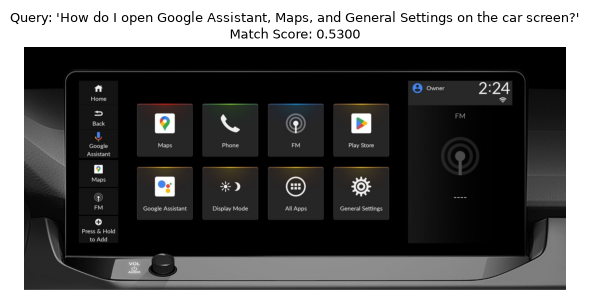

USER QUERY       : Infotainment screen showing Owner profile, clock at 2:24, and VOL AUDIO knob
SIMILARITY SCORE : 0.4295
LINKED IMAGE PATH: D:\multimodel-rag-lab\Document\IVI_Data.jpg
--------------------------------------------------------------------------------


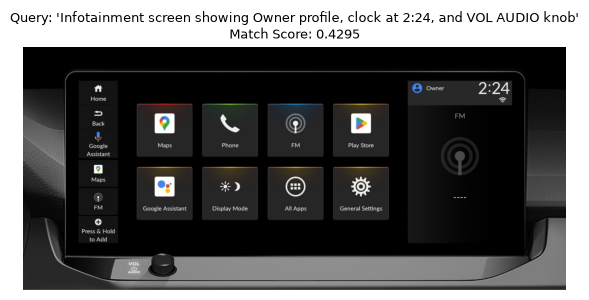

USER QUERY       : Black tiles with rainbow glowing top borders in red, green, blue, and yellow
SIMILARITY SCORE : 0.0758
LINKED IMAGE PATH: D:\multimodel-rag-lab\Document\IVI_Data.jpg
--------------------------------------------------------------------------------


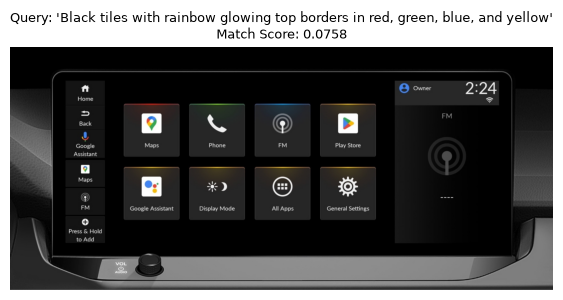

In [6]:
# Import PIL Image to open and display the retrieved image file from disk
from PIL import Image

# Define a reusable retrieval function for Scenario 1
def retrieve_image_scenario_1(user_query: str, top_k: int = 1):
    # Step 1: Convert the user's text query into a 384-d vector using the same all-MiniLM-L6-v2 model
    query_vec = text_embedder.encode(user_query, normalize_embeddings=True).tolist()
    
    # Step 2: Search Qdrant for summary vectors with the highest cosine similarity
    results = qdrant_client.query_points(
        collection_name=COLLECTION_SCENARIO_1,               # Search in Scenario 1 collection
        query=query_vec,                                     # Query vector
        limit=top_k                                          # Number of matches to return
    ).points
    
    # Step 3: Fetch the top matching point and extract the linked image path
    best_match = results[0]                                  # Top result
    matched_img_path = best_match.payload["image_path"]      # Original image file path stored in payload
    score = best_match.score                                 # Cosine similarity score
    
    # Print query and match diagnostics
    print("=" * 80)
    print(f"USER QUERY       : {user_query}")
    print(f"SIMILARITY SCORE : {score:.4f}")
    print(f"LINKED IMAGE PATH: {matched_img_path}")
    print("-" * 80)
    
    # Step 4: Load and display the linked original image from disk
    img = Image.open(matched_img_path)                       # Open image using Pillow
    fig = plt.figure(figsize=(7, 3.5))                       # Create display figure
    plt.imshow(img)                                          # Render image pixels
    plt.title(f"Query: '{user_query}'\nMatch Score: {score:.4f}", fontsize=9)
    plt.axis("off")                                          # Hide axes
    plt.show()                                               # Display in notebook
    plt.close(fig)                                           # Free figure memory


# ---------------- TEST WITH 3 SAMPLE QUERIES ---------------- #

# Sample Query 1 (Keyword / App Search - Strong match in Scenario 1)
retrieve_image_scenario_1("How do I open Google Assistant, Maps, and General Settings on the car screen?")

# Sample Query 2 (Hardware / Status Bar Search - Tests OCR + VLM capture of volume knob and 2:24 clock)
retrieve_image_scenario_1("Infotainment screen showing Owner profile, clock at 2:24, and VOL AUDIO knob")

# Sample Query 3 (Fine Visual Detail Query - Tests Scenario 1's limitation on subtle colors/gradients)
retrieve_image_scenario_1("Black tiles with rainbow glowing top borders in red, green, blue, and yellow")